In [ ]:
##############################  Actividad 6 - Problema de clasificación para detección de fraude bancario  ##############################

##################################  Instalación de dependencias, importar librerías, reproducibilidad  ##################################

%pip install -q mlflow
#%pip install -q kagglehub scikit-learn scipy pandas matplotlib seaborn


import json, os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn
from scipy import stats
import kagglehub
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, RocCurveDisplay,
    precision_recall_curve, average_precision_score)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Fijar semilla de reproducibilidad
SEED = 42
RNG = np.random.default_rng(SEED)

# Evidencia de experimentos
OUT = Path('Actividad6_resultados'); OUT.mkdir(exist_ok=True)
DB_PATH = (Path.cwd() / 'mlflow.db').resolve()
ARTIFACT_ROOT = (Path.cwd() / 'mlflow_artifacts').resolve()
ARTIFACT_ROOT.mkdir(exist_ok=True)
mlflow.set_tracking_uri(f'sqlite:///{DB_PATH.as_posix()}')

# Crear el experimento con destino local y portable para artefactos.
EXPERIMENT_NAME = 'Credit card fraud detection'
experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
if experiment is None:
    mlflow.create_experiment(EXPERIMENT_NAME, artifact_location=ARTIFACT_ROOT.as_uri())
mlflow.set_experiment(EXPERIMENT_NAME)
print('MLflow SQLite:', DB_PATH, '| existe:', DB_PATH.exists())
print('Directorio de evidencias:', OUT.resolve())

MLflow SQLite: /content/mlflow.db | existe: True
Directorio de evidencias: /content/Actividad6_resultados


Using Colab cache for faster access to the 'creditcardfraud' dataset.
Archivo: /kaggle/input/creditcardfraud/creditcard.csv
Datos originales: (284807, 31)
Distribución original: {0: 284315, 1: 492}
Fraude original (%): 0.1727
Datos utilizados: (30000, 31)
Clases en muestra: {0: 29948, 1: 52}


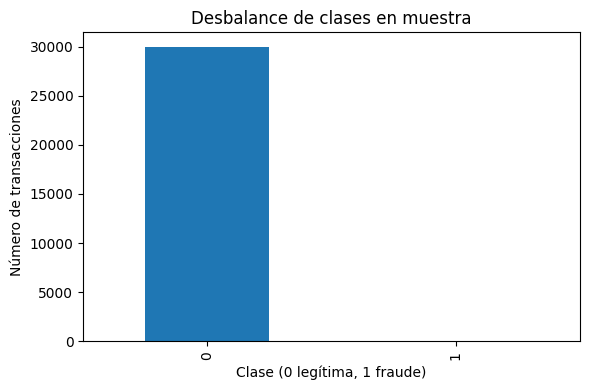

In [ ]:
#########################################  Descarga de dataset de Kaggle y preparación de datos  ########################################

# Descarga de dataset de Kaggle
dataset_dir = Path(kagglehub.dataset_download("mlg-ulb/creditcardfraud"))

files_csv = sorted(dataset_dir.rglob("creditcard.csv"))
if not files_csv:
    raise FileNotFoundError(f"No se encontró creditcard.csv en {dataset_dir}")
df_full = pd.read_csv(files_csv[0])

# Búsqueda de columnas clave
required = {'Class', 'Amount', 'Time'}
assert required.issubset(df_full.columns), 'Columnas esperadas no encontradas'
assert df_full['Class'].isin([0, 1]).all()
print('Archivo:', files_csv[0])
print('Datos originales:', df_full.shape)
print('Distribución original:', df_full['Class'].value_counts().to_dict())
print('Fraude original (%):', round(100 * df_full['Class'].mean(), 4))

# Muestreo estratificado
MAX_ROWS = 30000
if len(df_full) > MAX_ROWS:
    df, _ = train_test_split(df_full, train_size=MAX_ROWS, stratify=df_full['Class'], random_state=SEED)
else:
    df = df_full.copy()
df = df.reset_index(drop=True)
assert not df.isna().any().any(), 'Revisar valores faltantes'
X = df.drop(columns='Class')
y = df['Class'].to_numpy()
print('Datos utilizados:', df.shape)
print('Clases en muestra:', df['Class'].value_counts().to_dict())

# Separación del dataset para entrenamiento
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
df[['Class']].value_counts().rename('conteo').to_csv(OUT/'distribucion_clases.csv')
fig, ax = plt.subplots(figsize=(6, 4))
df['Class'].value_counts().sort_index().plot(kind='bar', ax=ax)
ax.set(xlabel='Clase (0 legítima, 1 fraude)', ylabel='Número de transacciones', title='Desbalance de clases en muestra')
fig.tight_layout(); fig.savefig(OUT/'distribucion_clases.png', dpi=160);
plt.show()



In [ ]:
###########################################  Definición del pipeline de evaluación y modelos  ###########################################

models = {
    'Dummy_mayoritaria': DummyClassifier(strategy='most_frequent'),
    'Regresion_logistica': Pipeline([('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1500, class_weight='balanced', random_state=SEED))]),
    'SVM_RBF': Pipeline([('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=SEED))]),
    'Random_Forest': RandomForestClassifier(n_estimators=120, max_depth=8, class_weight='balanced_subsample', random_state=SEED, n_jobs=-1)
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'roc_auc': 'roc_auc', 'f1': 'f1', 'recall': 'recall', 'precision': 'precision', 'accuracy': 'accuracy',
           'average_precision': 'average_precision'}

def metricas(y_true, proba, threshold=0.5):
    pred = (np.asarray(proba) >= threshold).astype(int)
    return {'accuracy': accuracy_score(y_true, pred),
            'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred, zero_division=0),
            'f1': f1_score(y_true, pred, zero_division=0),
            'roc_auc': roc_auc_score(y_true, proba),
            'average_precision': average_precision_score(y_true, proba),
            'fp': int(confusion_matrix(y_true, pred, labels=[0,1])[0,1]),
            'fn': int(confusion_matrix(y_true, pred, labels=[0,1])[1,0])}


In [ ]:
#################################################  Validación cruzada y MLflow  #################################################

rows = []
for name, estimator in models.items():
    with mlflow.start_run(run_name='CV_' + name):
        scores = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1, error_score='raise')
        row = {'modelo': name}
        for metric in scoring:
            vals = scores['test_' + metric]
            row[metric + '_media'] = float(np.mean(vals))
            row[metric + '_sd'] = float(np.std(vals, ddof=1))
            mlflow.log_metric('cv_' + metric + '_media', row[metric + '_media'])
            mlflow.log_metric('cv_' + metric + '_sd', row[metric + '_sd'])
            for k, val in enumerate(vals, 1):
                mlflow.log_metric('cv_' + metric + '_fold', float(val), step=k)
        mlflow.log_param('modelo', name)
        mlflow.log_param('seed', SEED)
        mlflow.log_param('n_folds', cv.n_splits)
        rows.append(row)

SELECTION_METRIC = 'average_precision_media'
cv_table = pd.DataFrame(rows).sort_values(SELECTION_METRIC, ascending=False)
display(cv_table.round(4))
cv_table.to_csv(OUT / 'comparacion_cv.csv', index=False)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.p

,modelo,roc_auc_media,roc_auc_sd,f1_media,f1_sd,recall_media,recall_sd,precision_media,precision_sd,accuracy_media,accuracy_sd,average_precision_media,average_precision_sd
3,Random_Forest,0.9505,0.0453,0.8085,0.0888,0.7238,0.1124,0.9267,0.1011,0.9994,0.0003,0.8116,0.1093
1,Regresion_logistica,0.9542,0.0411,0.3451,0.0441,0.8429,0.1019,0.2184,0.0351,0.9942,0.0016,0.7794,0.0610
2,SVM_RBF,0.9877,0.0181,0.2805,0.0971,0.1857,0.0568,0.6333,0.3416,0.9983,0.0004,0.4647,0.2740
0,Dummy_mayoritaria,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.9982,0.0002,0.0018,0.0002


In [ ]:
#########################################################  Selección del modelo  ########################################################

candidatos = cv_table[cv_table.modelo != 'Dummy_mayoritaria']
best_name = str(candidatos.iloc[0]['modelo'])
best_model = models[best_name]
best_model.fit(X_train, y_train)
val_proba = best_model.predict_proba(X_val)[:, 1]
print('Modelo seleccionado mediante CV por', SELECTION_METRIC, ':', best_name)
print('AUC de validación:', round(roc_auc_score(y_val, val_proba), 4))



Modelo seleccionado mediante CV por average_precision_media : Random_Forest
AUC de validación: 0.9479


Umbral seleccionado: 0.05


,umbral,accuracy,precision,recall,f1,roc_auc,average_precision,fp,fn,costo_hipotetico
0,0.05,0.9993,0.750,0.9,0.8182,0.9479,0.8441,3,1,13
15,0.20,0.9993,0.800,0.8,0.8000,0.9479,0.8441,2,2,22
45,0.50,0.9993,0.875,0.7,0.7778,0.9479,0.8441,1,3,31


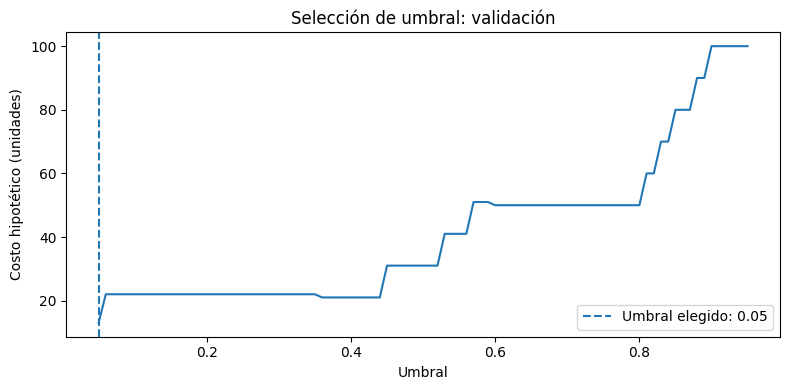

In [ ]:
##########################################################  Ajuste de umbrales  #########################################################

COSTO_FN = 10
COSTO_FP = 1

thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
threshold_rows = []
for t in thresholds:
    m = metricas(y_val, val_proba, t)
    threshold_rows.append({'umbral': float(t), **m,
                           'costo_hipotetico': COSTO_FN*m['fn'] + COSTO_FP*m['fp']})
threshold_table = pd.DataFrame(threshold_rows)
chosen = threshold_table.sort_values(['costo_hipotetico','umbral']).iloc[0]
chosen_threshold = float(chosen['umbral'])

print('Umbral seleccionado:', chosen_threshold)

display(threshold_table.loc[threshold_table.umbral.isin([0.20, 0.50, chosen_threshold])].round(4))
threshold_table.to_csv(OUT / 'busqueda_umbrales_validacion.csv', index=False)
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(threshold_table.umbral, threshold_table.costo_hipotetico)
ax.axvline(chosen_threshold, linestyle='--', label=f'Umbral elegido: {chosen_threshold:.2f}')
ax.set(xlabel='Umbral', ylabel='Costo hipotético (unidades)', title='Selección de umbral: validación')
ax.legend();
fig.tight_layout();
fig.savefig(OUT/'costo_vs_umbral.png', dpi=160);
plt.show()


,configuracion,accuracy,precision,recall,f1,roc_auc,average_precision,fp,fn
0,umbral_0.50,0.9990,0.75,0.6,0.6667,0.947,0.6068,2,4
1,umbral_0.05,0.9983,0.50,0.8,0.6154,0.947,0.6068,8,2


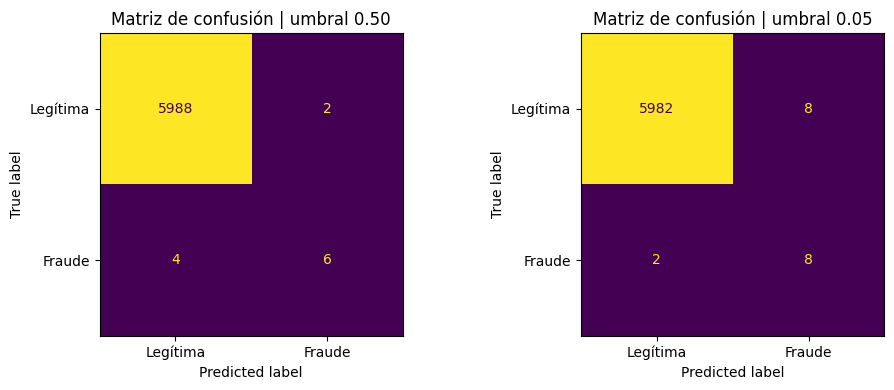

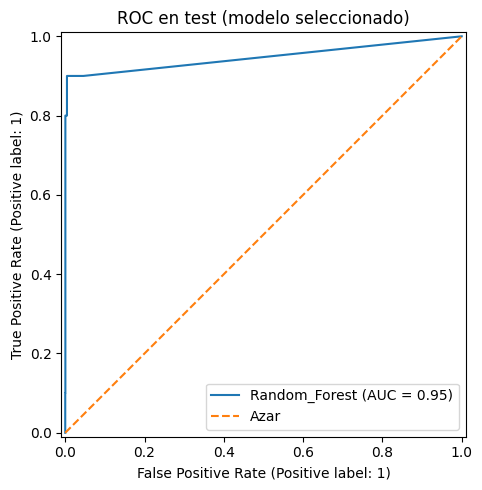

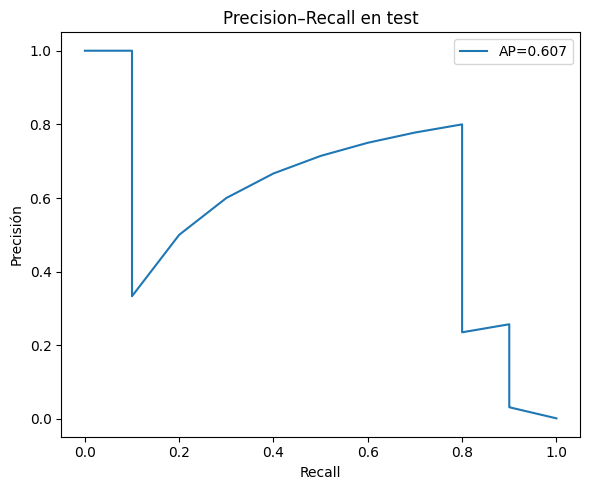

In [ ]:
#####################################################  Reentrenamiento y evaluación  ####################################################

best_model.fit(X_dev, y_dev)
test_proba = best_model.predict_proba(X_test)[:, 1]
metrics_05 = metricas(y_test, test_proba, 0.50)
metrics_opt = metricas(y_test, test_proba, chosen_threshold)

final_table = pd.DataFrame([
    {'configuracion':'umbral_0.50', **metrics_05},
    {'configuracion':f'umbral_{chosen_threshold:.2f}', **metrics_opt}
])
display(final_table.round(4))
final_table.to_csv(OUT/'metricas_test.csv', index=False)

fig, axs = plt.subplots(1,2,figsize=(10,4))

for ax, t in zip(axs, [0.50, chosen_threshold]):
    pred = (test_proba >= t).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0,1], display_labels=['Legítima','Fraude'], ax=ax, colorbar=False)
    ax.set_title(f'Matriz de confusión | umbral {t:.2f}')
fig.tight_layout(); fig.savefig(OUT/'matrices_confusion_test.png', dpi=160); plt.show()
fig, ax = plt.subplots(figsize=(6,5))

RocCurveDisplay.from_predictions(y_test, test_proba, ax=ax, name=best_name)
ax.plot([0,1],[0,1],'--',label='Azar'); ax.legend()
ax.set_title('ROC en test (modelo seleccionado)')
fig.tight_layout(); fig.savefig(OUT/'roc_test.png',dpi=160);
plt.show()

fig, ax = plt.subplots(figsize=(6,5))
p, r, _ = precision_recall_curve(y_test, test_proba)
ax.plot(r,p,label=f'AP={average_precision_score(y_test,test_proba):.3f}')
ax.set(xlabel='Recall',ylabel='Precisión',title='Precision–Recall en test')
ax.legend(); fig.tight_layout(); fig.savefig(OUT/'precision_recall_test.png',dpi=160);
plt.show()


{
  "tasa_A": 0.678,
  "tasa_B": 0.872,
  "diferencia_B_menos_A": 0.19399999999999995,
  "z": 10.388303320472318,
  "p_valor_bilateral": 2.80294765886953e-25,
  "ic95_diferencia_aprox": [
    0.1583985004360771,
    0.2296014995639228
  ],
  "Nota": "Simulación con tasas prefijadas."
}


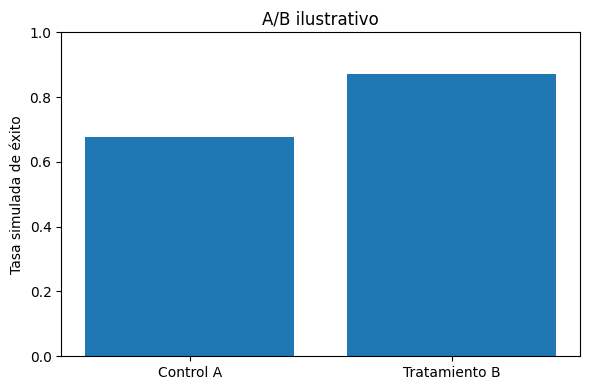

In [ ]:
############################################################  Simulación A/B  ###########################################################

rng_ab = np.random.default_rng(SEED)

n_a = n_b = 1000
A = rng_ab.binomial(1, 0.68, size=n_a)
B = rng_ab.binomial(1, 0.88, size=n_b)
p_a, p_b = float(A.mean()), float(B.mean())
diff = p_b - p_a
pooled = (A.sum()+B.sum()) / (n_a+n_b)
se_null = np.sqrt(pooled * (1-pooled) * (1/n_a+1/n_b))
z = diff/se_null
p_value = float(2 * stats.norm.sf(abs(z)))
se_ci = np.sqrt(p_a * (1-p_a)/n_a+p_b * (1-p_b)/n_b)
ci = (diff-1.96 * se_ci,diff + 1.96 * se_ci)
ab_result = {'tasa_A':p_a,'tasa_B':p_b, 'diferencia_B_menos_A':diff, 'z':float(z), 'p_valor_bilateral':p_value,
             'ic95_diferencia_aprox':list(map(float,ci)), 'Nota':'Simulación con tasas prefijadas.'}
print(json.dumps(ab_result,indent=2,ensure_ascii=False))

(OUT/'ab_simulado.json').write_text(json.dumps(ab_result,indent=2,ensure_ascii=False),encoding='utf-8')
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(['Control A','Tratamiento B'],[p_a,p_b])
ax.set(ylim=(0,1),ylabel='Tasa simulada de éxito',title='A/B ilustrativo')
fig.tight_layout();fig.savefig(OUT/'ab_simulado.png',dpi=160);
plt.show()


In [ ]:
###########################################################  Evidencia MLflow  #########################################################

with mlflow.start_run(run_name='Evaluacion_final_' + best_name):
    mlflow.log_params({'modelo_seleccionado':best_name,'umbral_elegido':chosen_threshold, 'costo_FN_hipotetico':COSTO_FN,
        'costo_FP_hipotetico':COSTO_FP, 'seed':SEED,'datos':'Kaggle_mlg-ulb/creditcardfraud', 'muestra_utilizada':len(df),
        'registros_originales':len(df_full),'criterio_seleccion':'cv_' + SELECTION_METRIC})

    for label, metrics in [('default',metrics_05),('optimizado',metrics_opt)]:
        for k,v in metrics.items():
            mlflow.log_metric(f'test_{label}_{k}',float(v))

    mlflow.log_metric('ab_simulado_p_bilateral',p_value)
    mlflow.log_metric('ab_simulado_diferencia_tasas',diff)
    mlflow.set_tags({'ab':'simulacion_ilustrativa','deployment_ready':'false'})
    mlflow.sklearn.log_model(best_model, name='modelo_final', skops_trusted_types=['sklearn.tree._tree.Tree'])
    mlflow.log_artifacts(str(OUT), artifact_path='evidencias')
    print('Experimentos y artefactos registrados en MLflow.')

Experimentos y artefactos registrados en MLflow.


In [ ]:
########################################################  Descarga de evidencias  #######################################################

import shutil
import sqlite3

# Se exportan BD, artefactos y resultados
EVIDENCIA = Path('Evidencia')
if EVIDENCIA.exists():
    shutil.rmtree(EVIDENCIA)
EVIDENCIA.mkdir()
shutil.copytree(OUT, EVIDENCIA / 'resultados')

with sqlite3.connect(str(DB_PATH)) as source, sqlite3.connect(str(EVIDENCIA / 'mlflow.db')) as target:
    source.backup(target)
if ARTIFACT_ROOT.exists():
    shutil.copytree(ARTIFACT_ROOT, EVIDENCIA / 'mlflow_artifacts')

(EVIDENCIA / 'LEEME_MLFLOW.txt').write_text(
    'Para abrir la UI en una carpeta extraida:\n'
    'mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000\n'
    'Los artefactos pueden conservar rutas absolutas de Colab; si se mueve la carpeta, '
    'puede ser necesario reconfigurar artifact_location en la base de datos o volver a registrar los experimentos.\n',
    encoding='utf-8')
zip_path = shutil.make_archive('evidencias_completas', 'zip', root_dir='.', base_dir=str(EVIDENCIA))
print('Base de datos incluida:', (EVIDENCIA / 'mlflow.db').exists())
print('ZIP generado:', zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print('ZIP disponible en el directorio de trabajo.')


Base de datos incluida: True
ZIP generado: /content/evidencias_completas.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>